c:\Users\Paimon\miniconda3\envs\ml_project\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Paimon\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1
Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contact

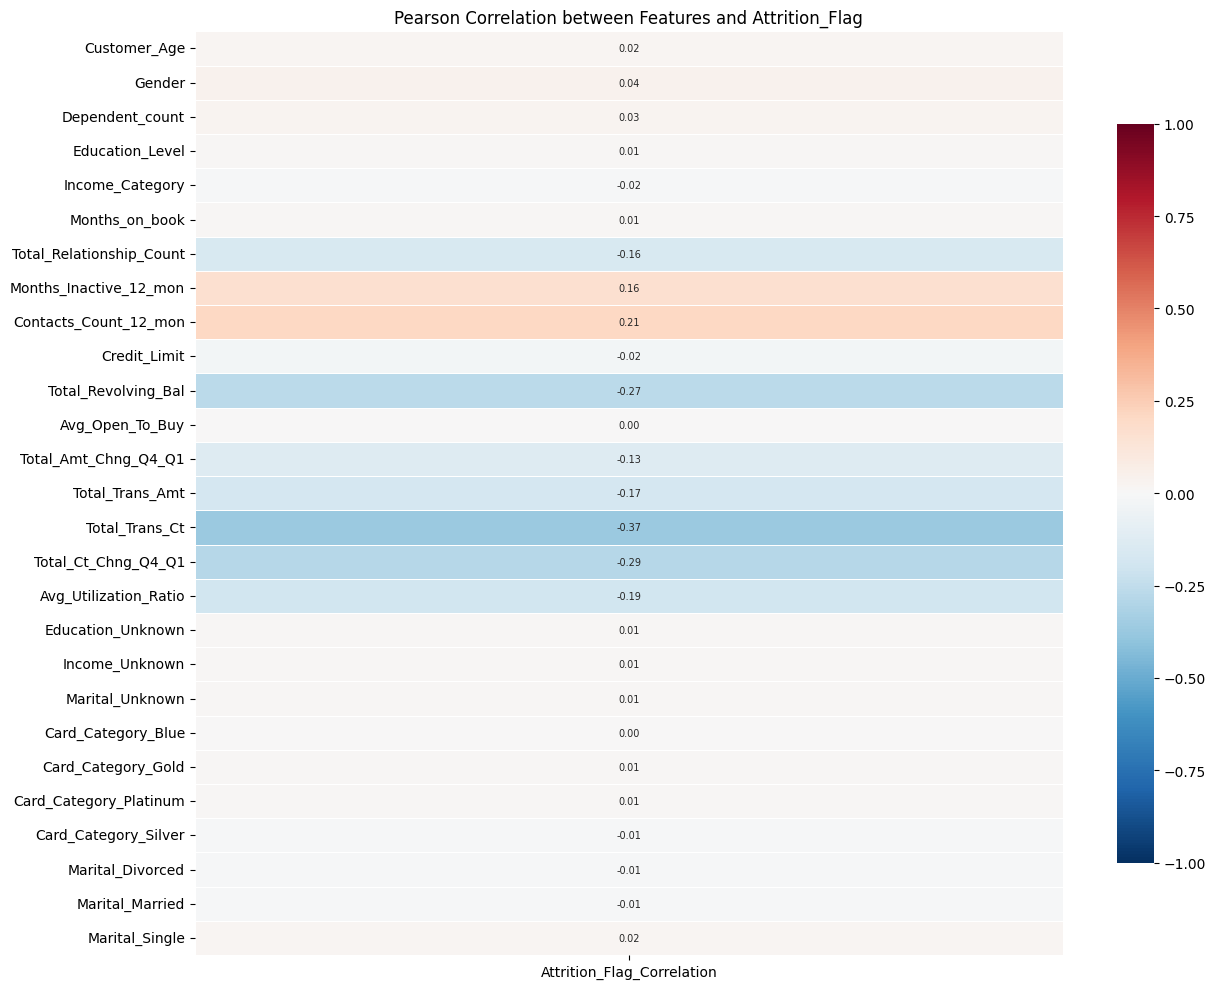

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

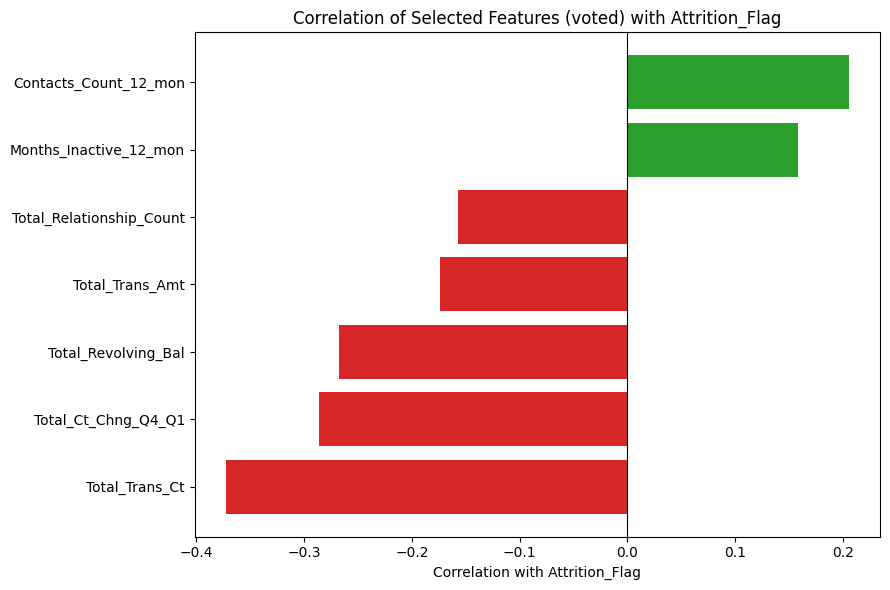

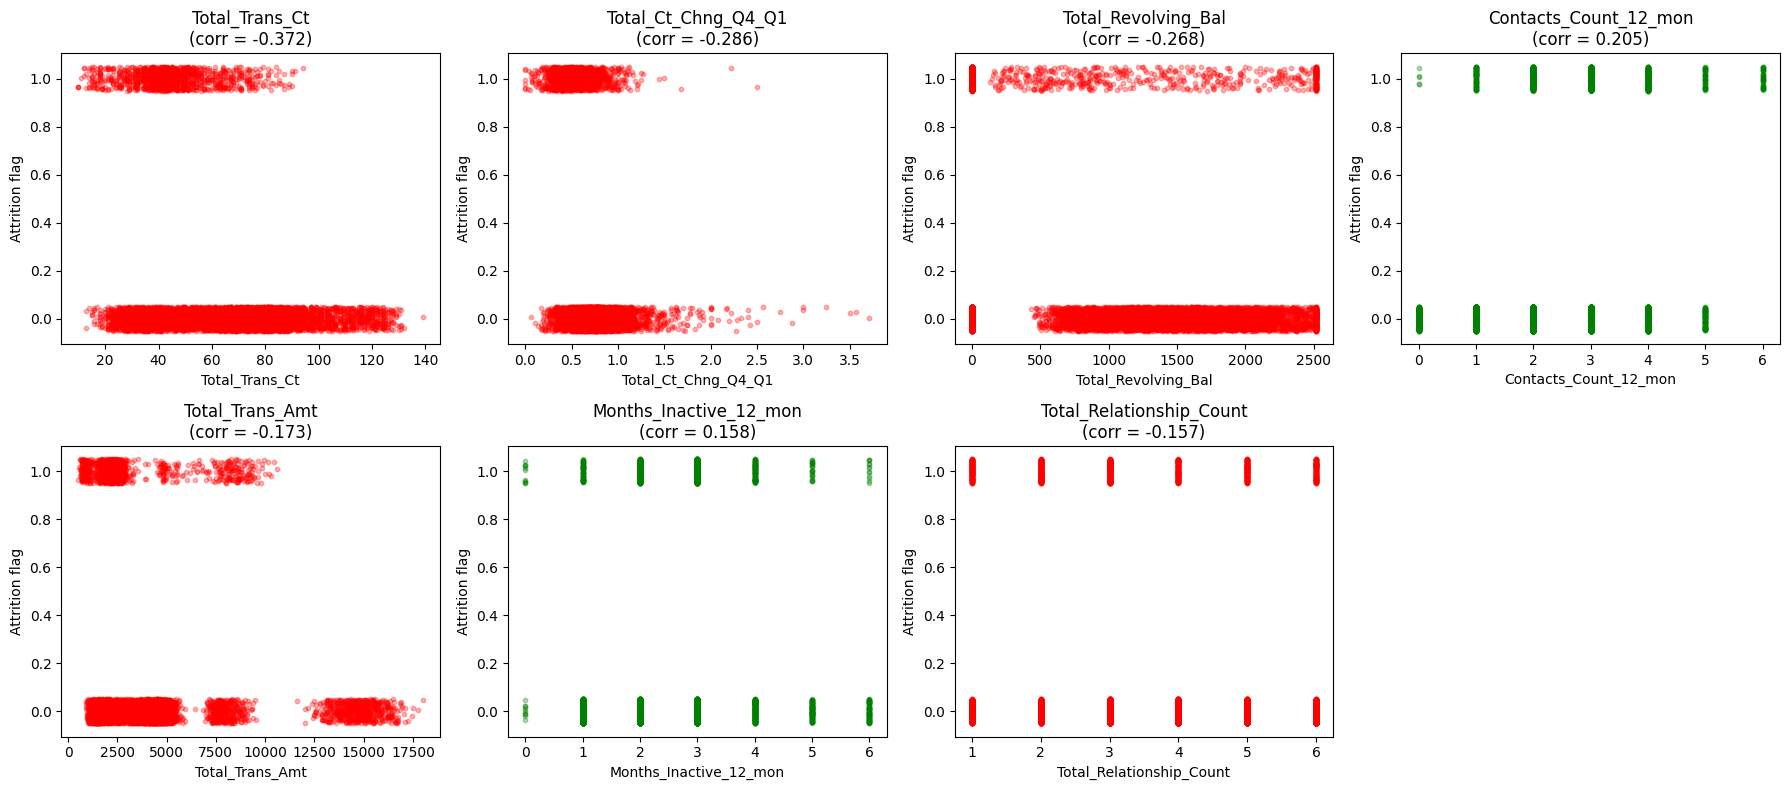

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068
                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692

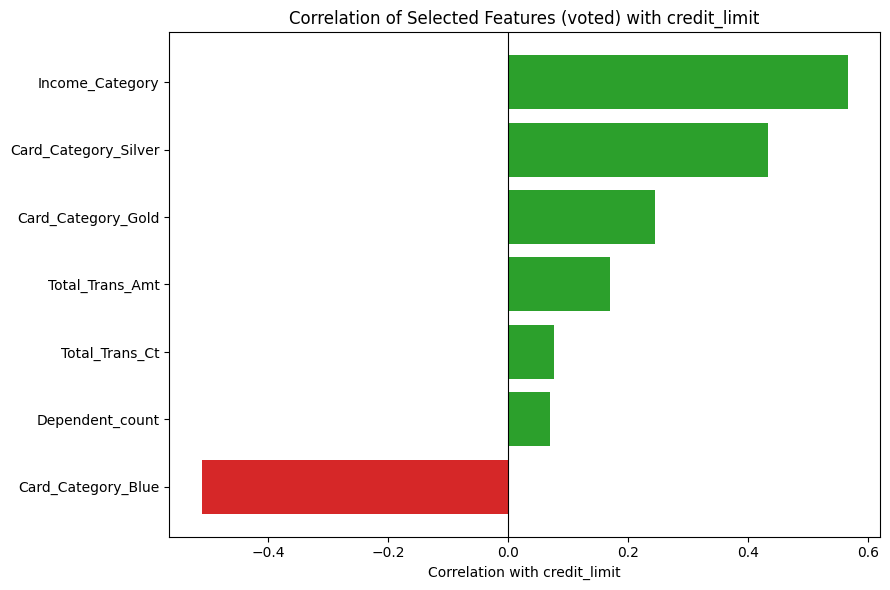

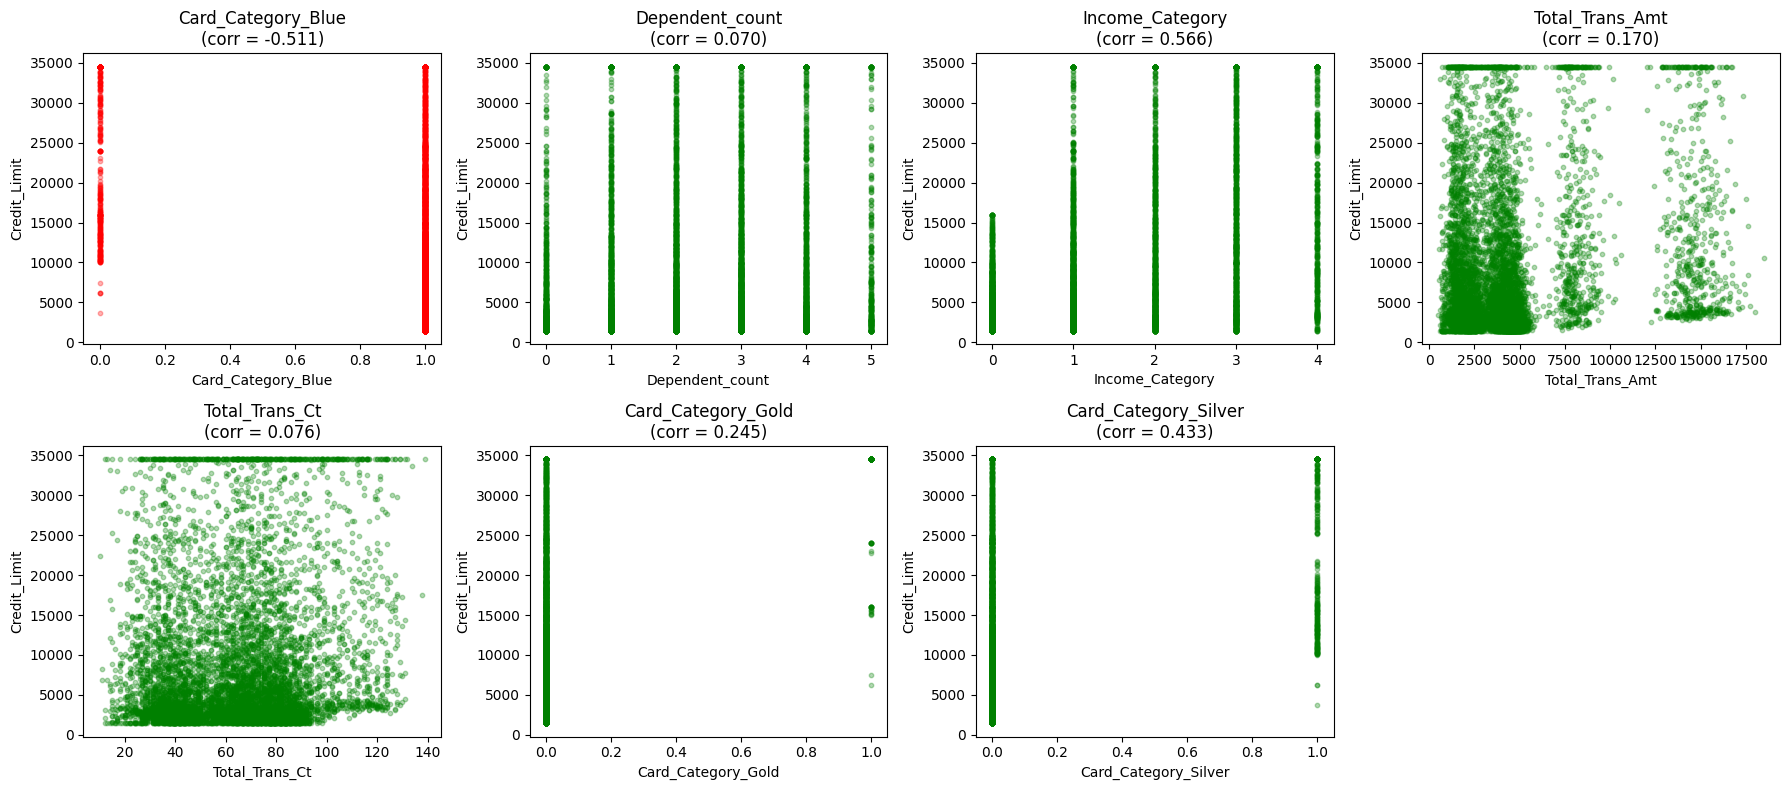

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


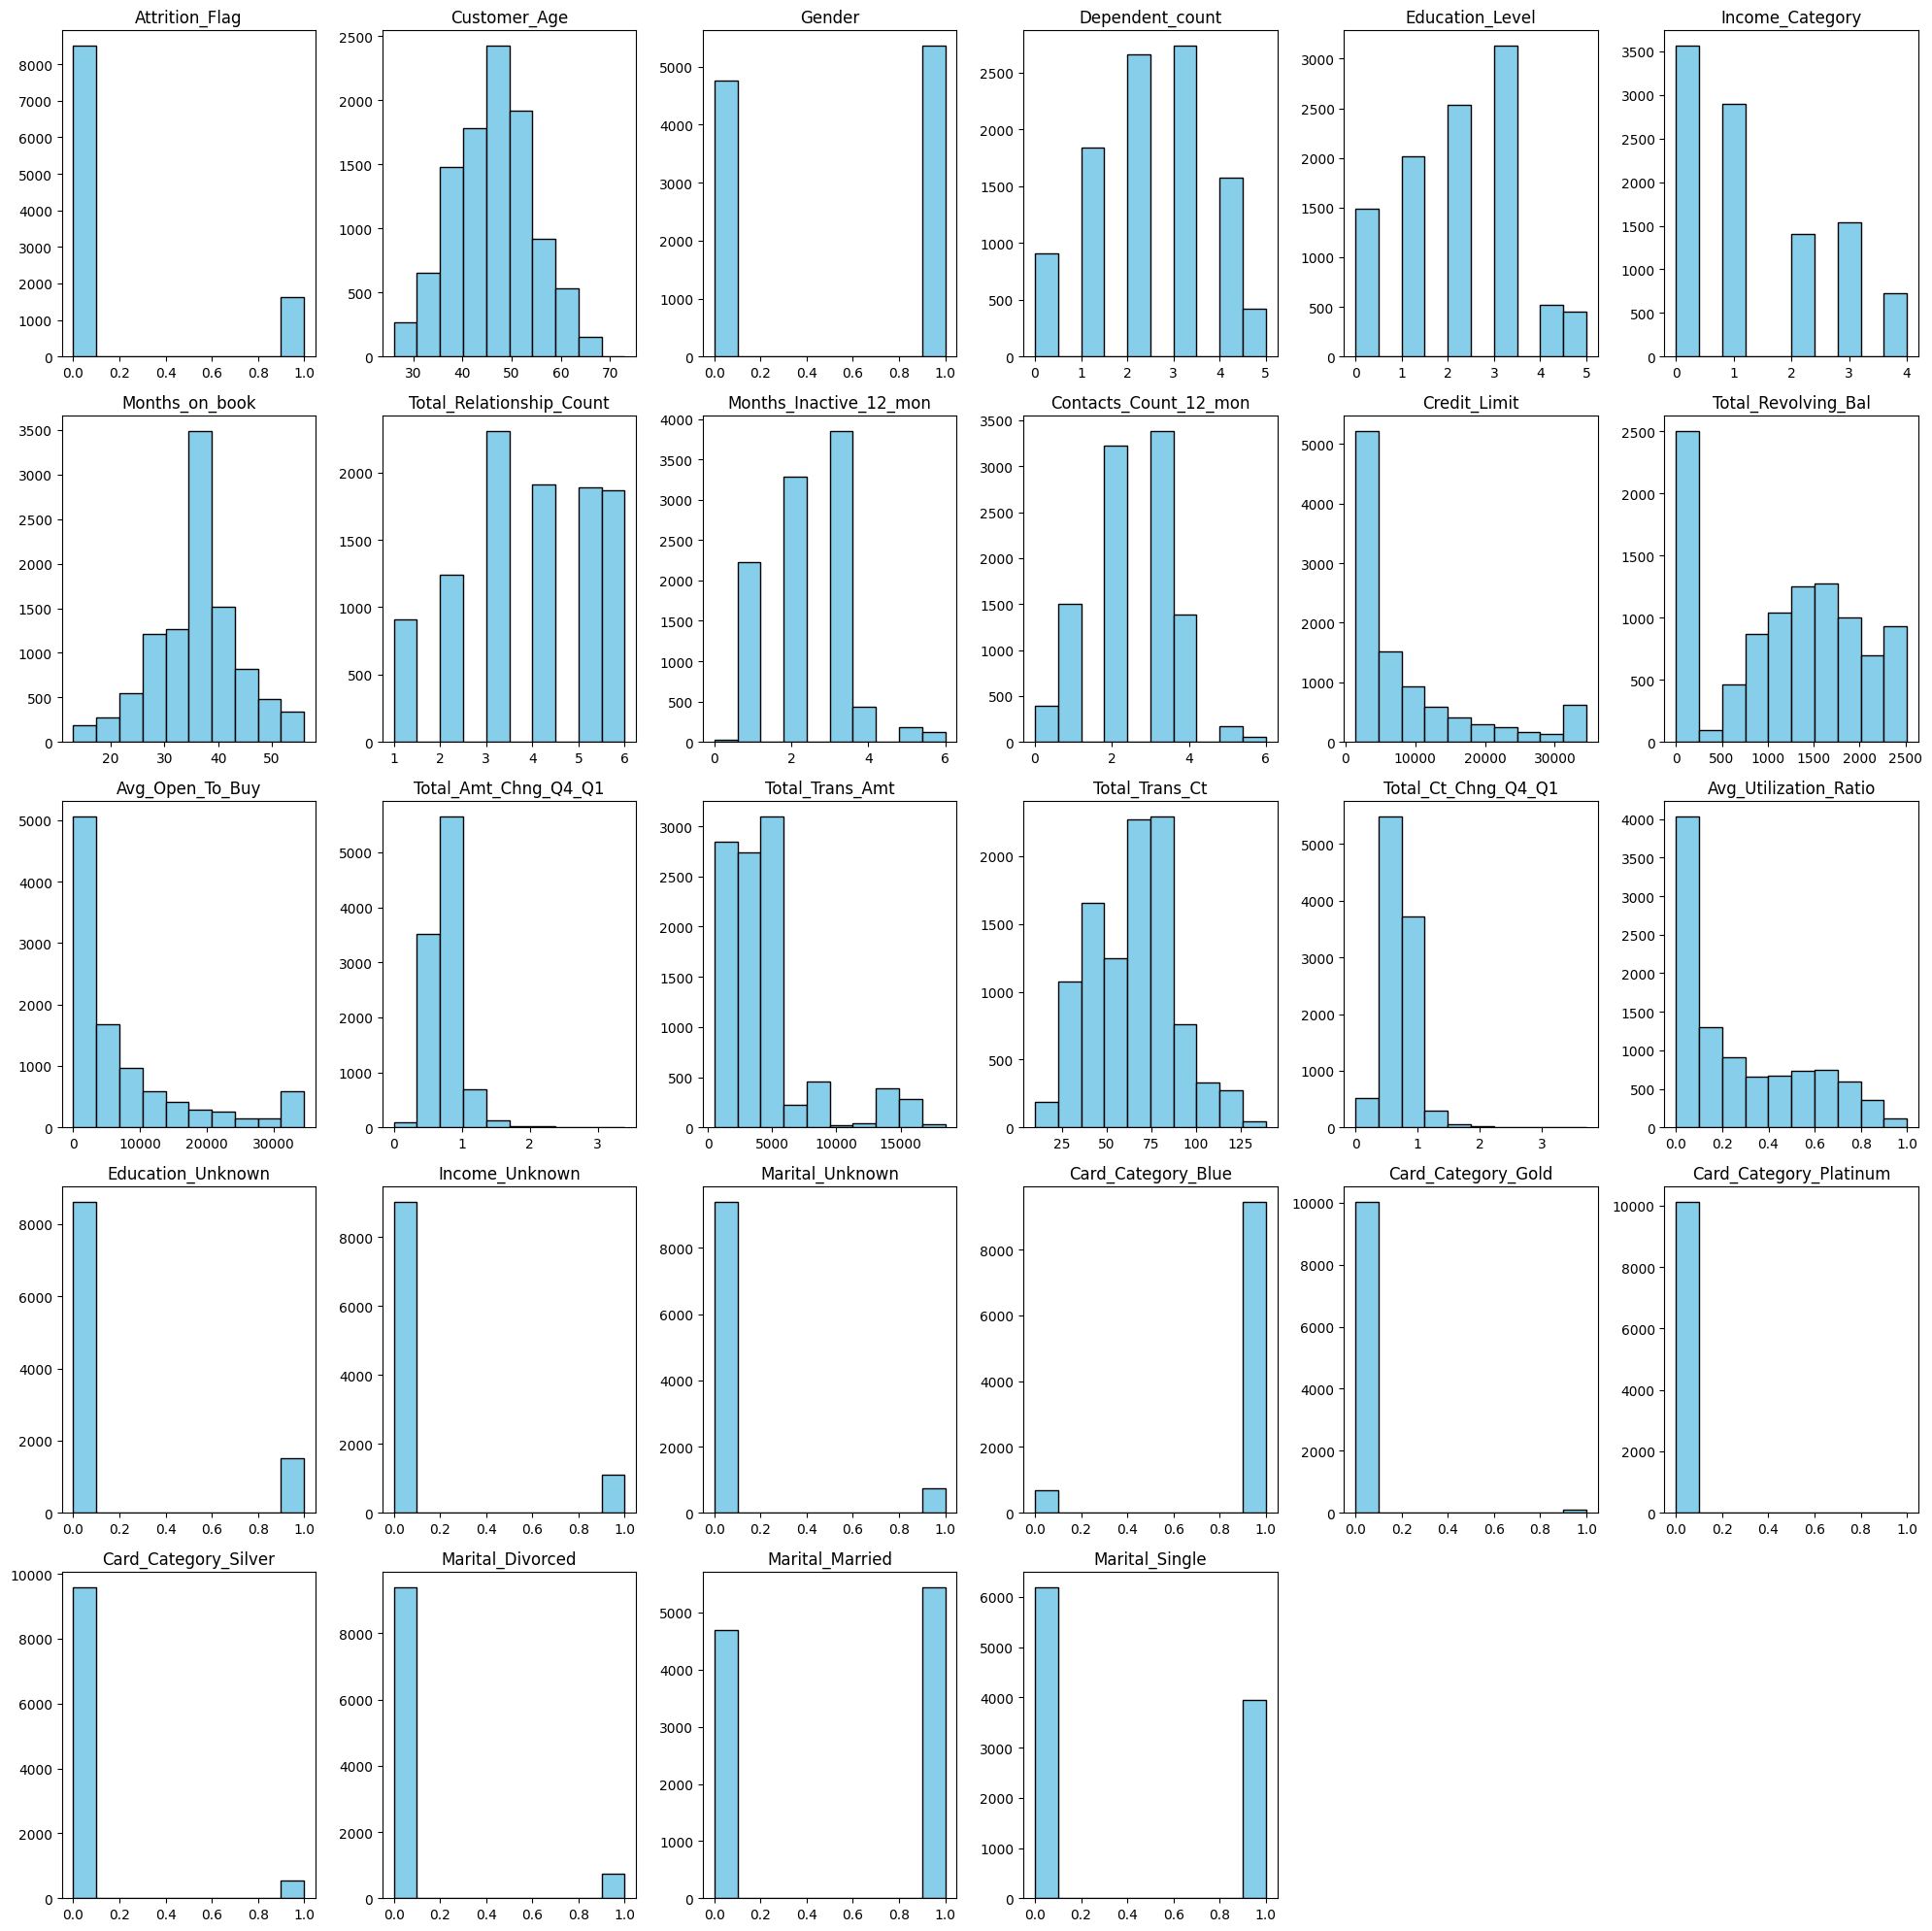

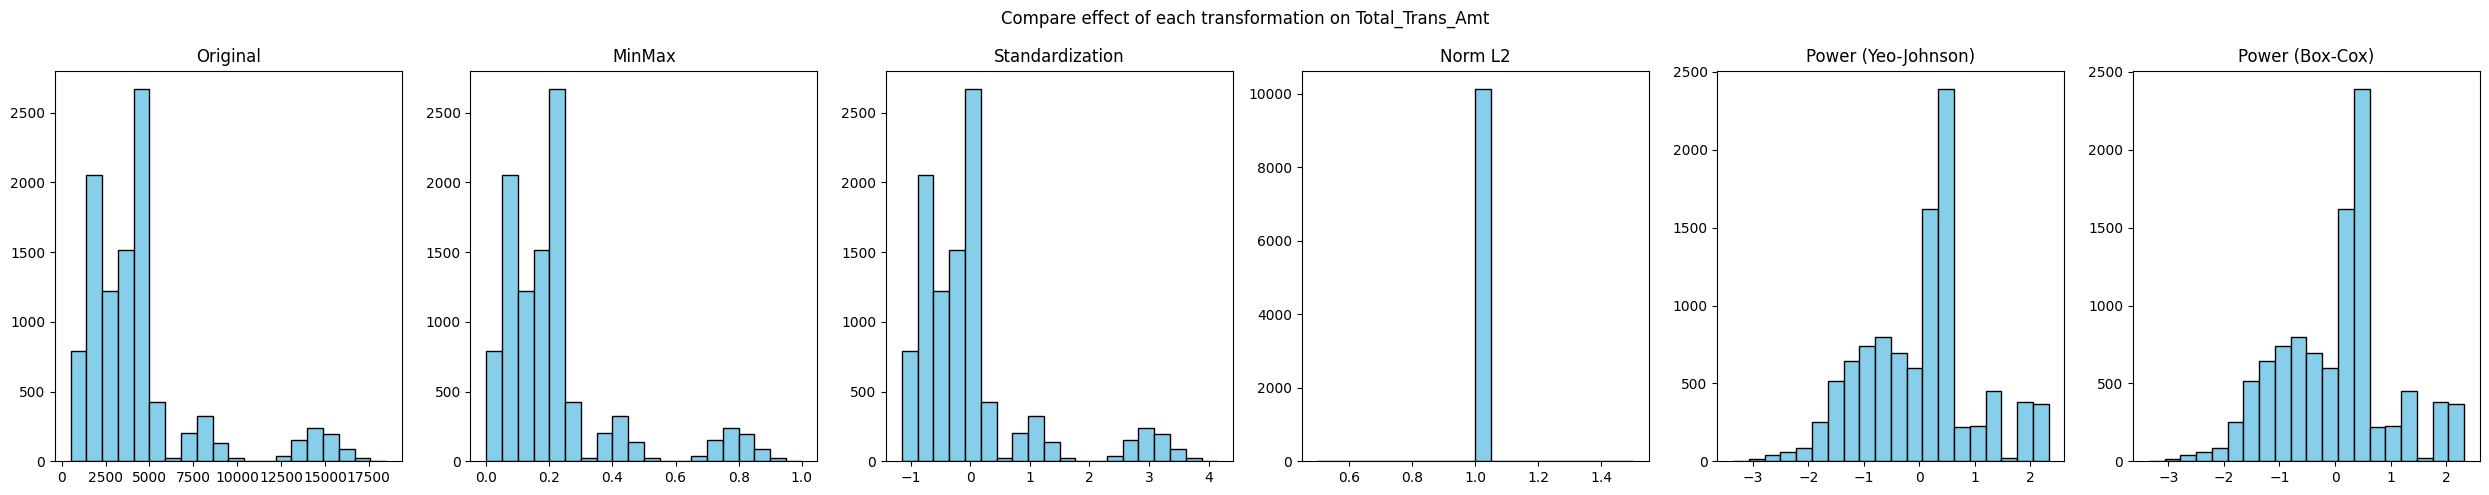

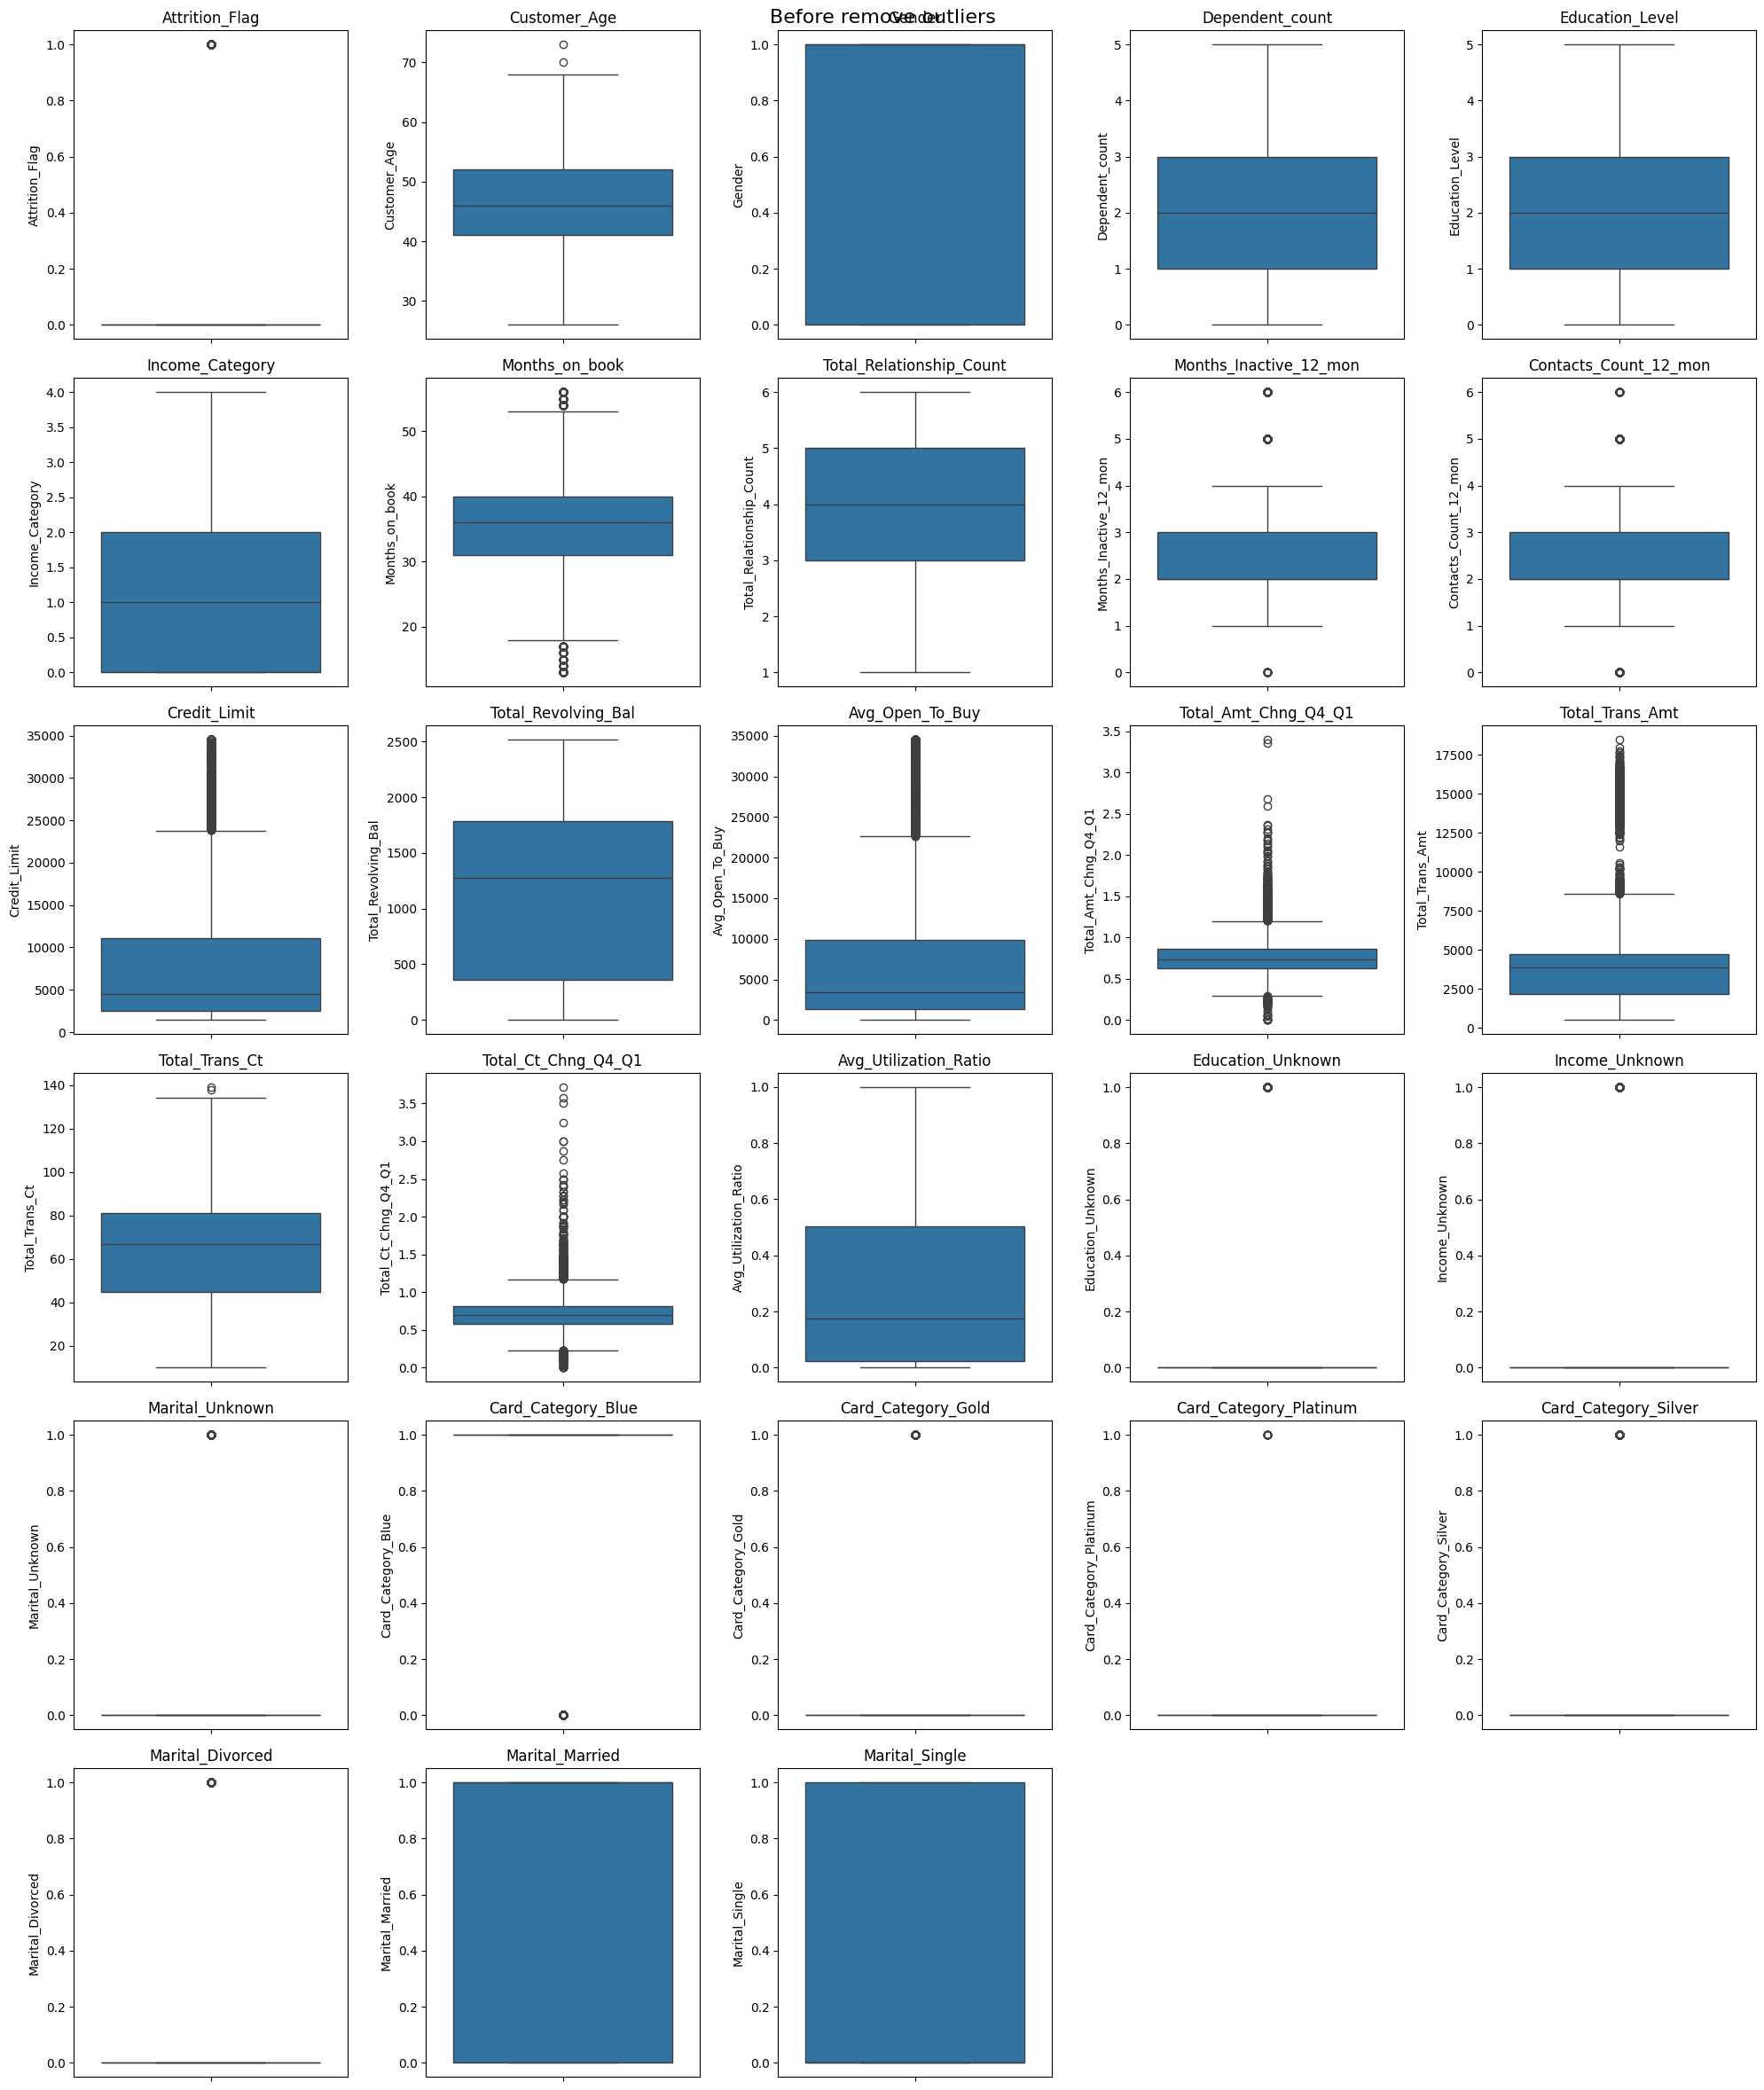

In [1]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test


continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']

scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()

Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

In [3]:
class BayesianLinearRegression:
    """alpha = weight prior precision, beta = noise precision.
    evidence=True เรียนรู้ทั้งสองค่าจาก marginal likelihood"""

    def __init__(self, alpha=1.0, beta=None, evidence=True, max_iter=300, tol=1e-6):
        self.alpha = alpha
        self.beta = beta
        self.evidence = evidence
        self.max_iter = max_iter
        self.tol = tol
        self.mu_post = None
        self.Sigma_post = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, d = X.shape

        # center เพื่อไม่ให้ prior หด intercept
        self.x_mean_ = X.mean(axis=0)
        self.y_mean_ = y.mean()
        Xc = X - self.x_mean_
        yc = y - self.y_mean_

        if self.beta is None:
            self.beta = 1.0 / np.var(yc)

        XtX = Xc.T @ Xc
        Xty = Xc.T @ yc
        eig = np.linalg.eigvalsh(XtX)

        for _ in range(self.max_iter if self.evidence else 1):
            Sigma = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
            m = self.beta * Sigma @ Xty
            if not self.evidence:
                break

            lam = self.beta * eig
            gamma = np.sum(lam / (self.alpha + lam))      # effective number of parameters
            alpha_new = gamma / max(m @ m, 1e-12)
            rss = np.sum((yc - Xc @ m) ** 2)
            beta_new = (n - gamma) / max(rss, 1e-12)

            converged = (abs(alpha_new - self.alpha) < self.tol * self.alpha and
                         abs(beta_new - self.beta) < self.tol * self.beta)
            self.alpha, self.beta = alpha_new, beta_new
            if converged:
                break

        self.Sigma_post = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
        self.w_ = self.beta * self.Sigma_post @ Xty
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.w_
        self.mu_post = np.r_[self.intercept_, self.w_].reshape(-1, 1)
        return self

    def predict(self, X, return_std=False):
        X = np.asarray(X, dtype=float)
        y_mean = X @ self.w_ + self.intercept_
        if return_std:
            Xc = X - self.x_mean_
            var = np.sum(Xc @ self.Sigma_post * Xc, axis=1) + 1.0 / self.beta
            return y_mean, np.sqrt(var)
        return y_mean

In [4]:
model = BayesianLinearRegression()
model.fit(Xr_train_scaled.values, yr_train)

y_pred, y_std = model.predict(Xr_test_scaled.values, return_std=True)

print("alpha =", model.alpha, " beta =", model.beta)
print("95% interval coverage =", np.mean(np.abs(np.asarray(yr_test).ravel() - y_pred) <= 1.96 * y_std))

alpha = 1.7171048369931483e-08  beta = 2.6608141778898465e-08
95% interval coverage = 0.926949654491609


In [5]:
# evaluate
r2 = r2_score(yr_test, y_pred)
mse = mean_squared_error(yr_test, y_pred)
mae = mean_absolute_error(yr_test, y_pred)

print(f"R² = {r2:.4f}")
print(f"MSE = {mse:.2f}")
print(f"MAE = {mae:.2f}")

R² = 0.5386
MSE = 38195831.17
MAE = 4250.91


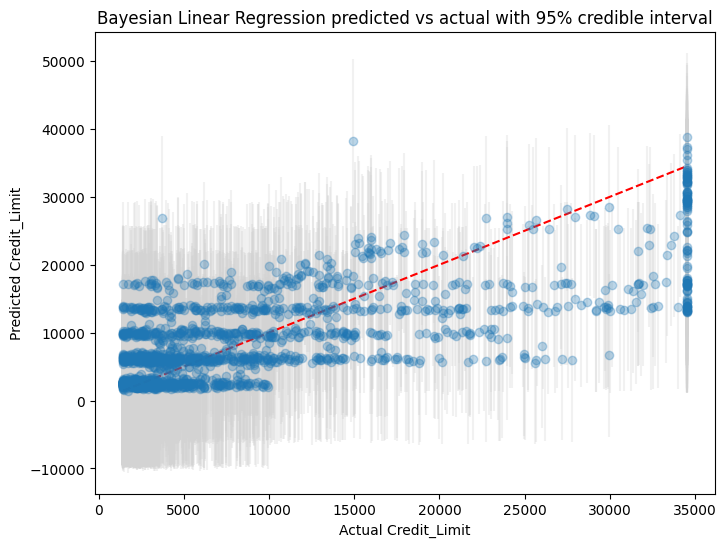

In [6]:
# plot predicted vs actual พร้อม credible interval
plt.figure(figsize=(8,6))
plt.errorbar(yr_test, y_pred, yerr=1.96*y_std, fmt='o', alpha=0.3, ecolor='lightgray')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual Credit_Limit')
plt.ylabel('Predicted Credit_Limit')
plt.title('Bayesian Linear Regression predicted vs actual with 95% credible interval')
plt.show()

In [7]:
sk_model = BayesianRidge()
sk_model.fit(Xr_train_scaled.values, yr_train)
y_pred_sk = sk_model.predict(Xr_test_scaled.values)

print("sklearn R²:", r2_score(yr_test, y_pred_sk))
print("weight ของเรา:", model.mu_post.ravel())
print("weight ของ sklearn:", np.r_[sk_model.intercept_, sk_model.coef_])

sklearn R²: 0.5385679388440179
weight ของเรา: [ 21985.33549328   3691.82002689 -19298.99595591   1057.86784259
  -3522.34810658   -454.30330035   -800.66864596    221.34118172]
weight ของ sklearn: [ 21985.33524864   3691.82002683 -19298.99571075   1057.86784327
  -3522.34786117   -454.30330053   -800.66840192    221.34118176]
